# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______________________ &nbsp;&nbsp; **Roll No.:** ____________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

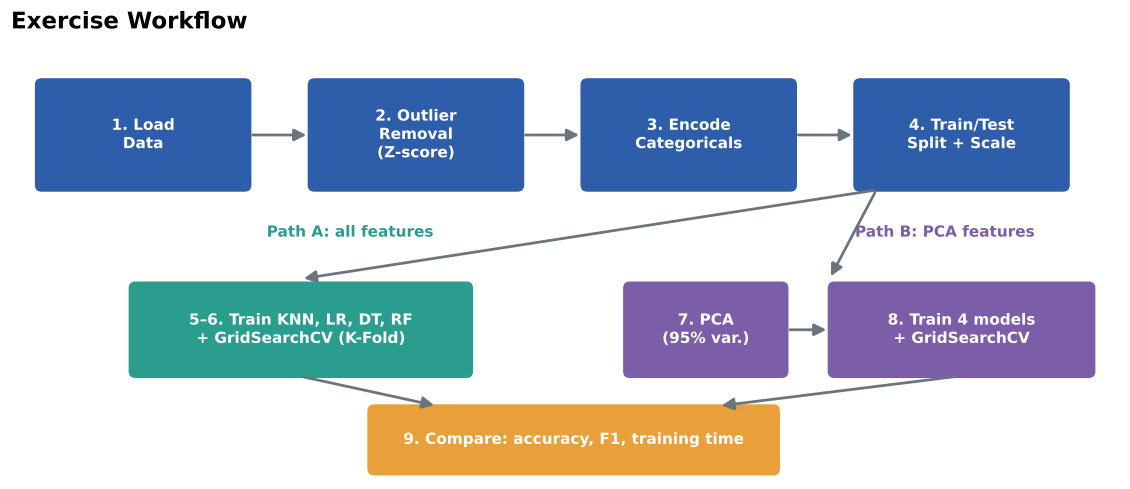

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
# The notebook expects the file at Exercise/heart.csv; a few fallbacks are tried for convenience
candidates = ["Exercise/heart.csv", "heart.csv", "heart - heart.csv", "heart_-_heart.csv"]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError("heart.csv not found. Place it in the 'Exercise' folder next to this notebook.")

df = pd.read_csv(path)
print("Loaded from:", path)
df.head()

Loaded from: Exercise/heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Dimensions (rows, columns):", df.shape)
print("\nColumn names:\n", list(df.columns))
print("\nData types:")
print(df.dtypes)
print()
df.info()
print("\nSummary statistics (numerical):")
display(df.describe().T)

Dimensions (rows, columns): (918, 12)

Column names:
 ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


### 1.3 Check for missing values

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

# Hidden missing values: physiologically impossible zeros
print("\nRecords with Cholesterol == 0:", (df["Cholesterol"] == 0).sum())
print("Records with RestingBP   == 0:", (df["RestingBP"] == 0).sum())

Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0

Records with Cholesterol == 0: 172
Records with RestingBP   == 0: 1


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
0    410
1    508
Name: count, dtype: int64

Percentage:
HeartDisease
0    44.66
1    55.34
Name: proportion, dtype: float64


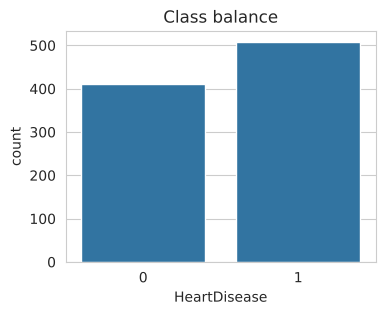

In [5]:
counts = df["HeartDisease"].value_counts().sort_index()
print(counts)
print("\nPercentage:")
print((df["HeartDisease"].value_counts(normalize=True).sort_index() * 100).round(2))

plt.figure(figsize=(4, 3))
sns.countplot(x="HeartDisease", data=df)
plt.title("Class balance")
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset has **918 rows and 12 columns** (11 features + the target `HeartDisease`). Five columns are text-based (object/string): `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope`; the other seven are numeric. **No missing values** are flagged by `isnull()` (0 in every column).
>
> However, there are **hidden missing values**: `Cholesterol` has **172 records equal to 0** (about 18.7% of the data) and `RestingBP` has **1 record equal to 0**. Both are medically impossible and are really missing measurements recorded as 0. The classes are fairly balanced: 508 patients with heart disease (55.3%) vs 410 without (44.7%).

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

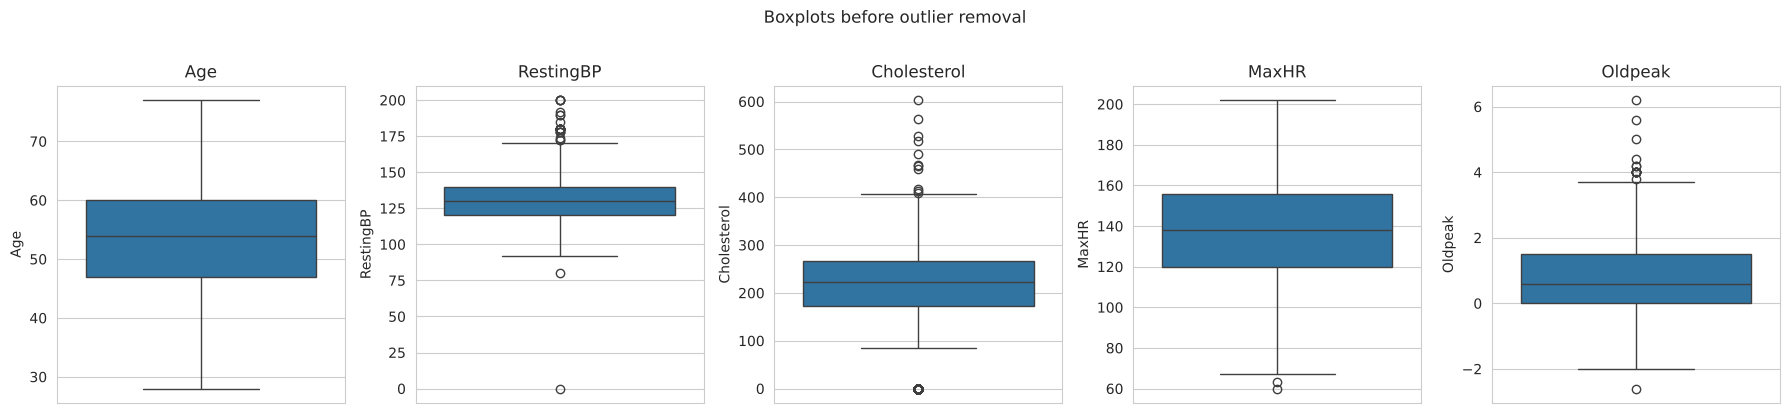

In [6]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots before outlier removal", y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = pd.DataFrame(stats.zscore(df[num_cols]), columns=num_cols, index=df.index)
z_scores.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [8]:
outlier_mask_per_feature = z_scores.abs() > 3
print("Outliers per feature (|z| > 3):")
print(outlier_mask_per_feature.sum())

outlier_rows = outlier_mask_per_feature.any(axis=1)
print("\nNumber of records containing at least one outlier:", outlier_rows.sum())
display(df[outlier_rows])

Outliers per feature (|z| > 3):
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Number of records containing at least one outlier: 19


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
76,32,M,ASY,118,529,0,Normal,130,N,0.0,Flat,1
109,39,M,ATA,190,241,0,Normal,106,N,0.0,Up,0
149,54,M,ASY,130,603,1,Normal,125,Y,1.0,Flat,1
166,50,M,ASY,140,231,0,ST,140,Y,5.0,Flat,1
241,54,M,ASY,200,198,0,Normal,142,Y,2.0,Flat,1
324,46,M,ASY,100,0,1,ST,133,N,-2.6,Flat,1
365,64,F,ASY,200,0,0,Normal,140,Y,1.0,Flat,1
390,51,M,ASY,140,0,0,Normal,60,N,0.0,Flat,1
399,61,M,NAP,200,0,1,ST,70,N,0.0,Flat,1
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


### 2.4 Remove the outliers and display the new shape

Shape before removal: (918, 12)
Shape after removal:  (899, 12)
Records removed:      19


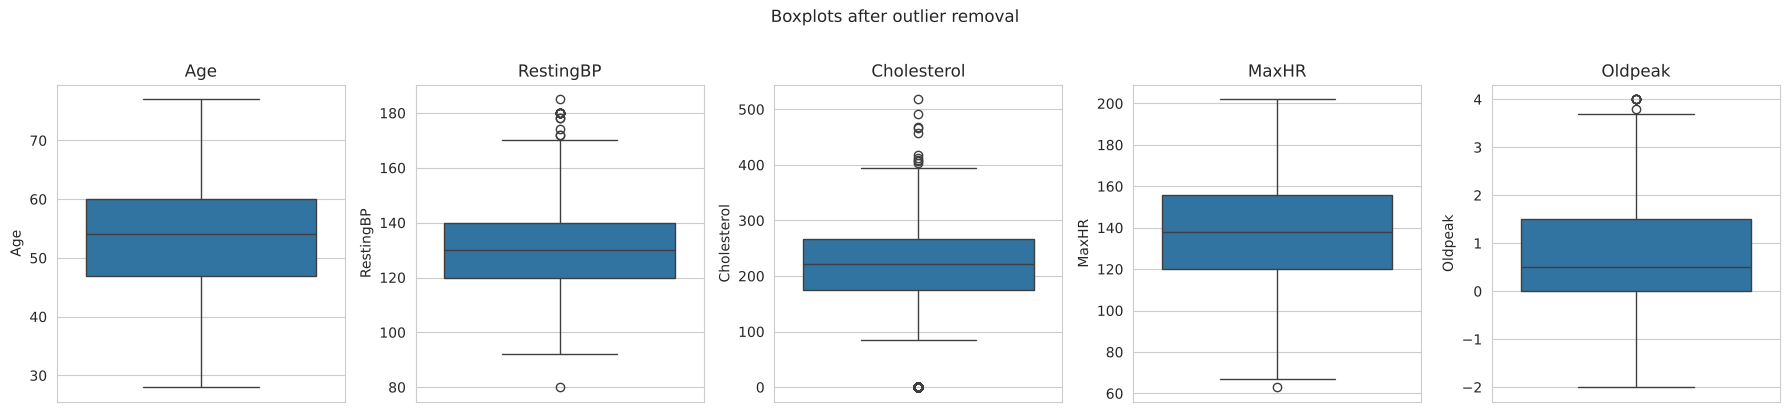

In [9]:
print("Shape before removal:", df.shape)
df_clean = df[~outlier_rows].reset_index(drop=True)
print("Shape after removal: ", df_clean.shape)
print("Records removed:     ", df.shape[0] - df_clean.shape[0])

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots after outlier removal", y=1.02)
plt.tight_layout()
plt.show()

**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> **19 records** were removed (918 -> 899 rows). The outliers per feature were: `RestingBP` 8, `Oldpeak` 7, `Cholesterol` 3, `MaxHR` 1 and `Age` 0, so **`RestingBP` contributed the most** (the 8 records include the impossible `RestingBP = 0` row and several very high readings), closely followed by `Oldpeak`. No record had outliers in more than one feature (8+7+3+1 = 19).
>
> Note: the Z-score method does **not** remove the 172 `Cholesterol = 0` records, because 0 is only about 1.8 standard deviations below the mean. These remain in the data (they are hidden missing values, not statistical outliers); in a fuller analysis they would be imputed, e.g. with the median of the non-zero values.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
cat_cols = df_clean.select_dtypes(exclude="number").columns.tolist()
print("Categorical features:", cat_cols)
for col in cat_cols:
    print(f"{col:15s} -> {df_clean[col].unique().tolist()}")

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Sex             -> ['M', 'F']
ChestPainType   -> ['ATA', 'NAP', 'ASY', 'TA']
RestingECG      -> ['Normal', 'ST', 'LVH']
ExerciseAngina  -> ['N', 'Y']
ST_Slope        -> ['Up', 'Flat', 'Down']


### 3.2 Apply Label Encoding

In [11]:
df_enc = df_clean.copy()

# Label Encoding for the binary features
binary_cols = ["Sex", "ExerciseAngina"]
label_encoders = {}
for col in binary_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    label_encoders[col] = le
    print(col, "->", {cls: int(code) for cls, code in zip(le.classes_, le.transform(le.classes_))})

df_enc[binary_cols].head()

Sex -> {'F': 0, 'M': 1}
ExerciseAngina -> {'N': 0, 'Y': 1}


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [12]:
# One-Hot Encoding for the nominal features (drop_first=True avoids the dummy-variable trap)
nominal_cols = ["ChestPainType", "RestingECG", "ST_Slope"]
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, drop_first=True, dtype=int)
print("New columns created:")
print([c for c in df_enc.columns if any(c.startswith(n + "_") for n in nominal_cols)])

New columns created:
['ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 3.4 Display the final encoded dataset

In [13]:
print("Shape of encoded dataset:", df_enc.shape)
print("Any text columns left?   ", df_enc.select_dtypes(exclude="number").shape[1] > 0)
df_enc.head()

Shape of encoded dataset: (899, 16)
Any text columns left?    False


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> - **Label Encoding** for the binary features `Sex` (F=0, M=1) and `ExerciseAngina` (N=0, Y=1). With only two categories there is no false ordering to worry about, and a single 0/1 column carries all the information.
> - **One-Hot Encoding** (with `drop_first=True`) for the nominal features `ChestPainType` (4 categories -> 3 columns), `RestingECG` (3 -> 2 columns) and `ST_Slope` (3 -> 2 columns). These have no natural order, so label encoding would impose a meaningless ranking (e.g. ASY > NAP > ATA) that distance-based and linear models would take literally. Dropping the first dummy avoids the dummy-variable trap (perfect multicollinearity).
>
> After encoding the dataset has **16 columns = 15 features + the target** (the 8 original non-nominal features plus 7 dummy columns). `FastingBS` was already numeric and was left unchanged.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df_enc.drop(columns="HeartDisease")
y = df_enc["HeartDisease"]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Features:", list(X.columns))

X shape: (899, 15) | y shape: (899,)
Features: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Class proportion in train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class proportion in test: ", y_test.value_counts(normalize=True).round(3).to_dict())

X_train: (719, 15) | X_test: (180, 15)
Class proportion in train: {1: 0.547, 0: 0.453}
Class proportion in test:  {1: 0.55, 0: 0.45}


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from the training set only
X_test_scaled = scaler.transform(X_test)         # apply the same parameters to the test set

print("Train mean (approx 0):", X_train_scaled.mean(axis=0).round(2)[:5], "...")
print("Train std  (approx 1):", X_train_scaled.std(axis=0).round(2)[:5], "...")
print("Test  mean (not exactly 0, as expected):", X_test_scaled.mean(axis=0).round(2)[:5], "...")

Train mean (approx 0): [ 0.  0. -0.  0.  0.] ...
Train std  (approx 1): [1. 1. 1. 1. 1.] ...
Test  mean (not exactly 0, as expected): [-0.09  0.11 -0.02 -0.17  0.07] ...


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I used **`StandardScaler`** (z-score standardisation: mean 0, standard deviation 1). KNN and Logistic Regression are sensitive to feature scale (e.g. `Cholesterol` in hundreds would dominate `Oldpeak` in the 0-6 range in distance calculations), and standardisation is also what PCA expects, since PCA looks at variance. It is also less distorted by the remaining extreme values than Min-Max scaling.
>
> If the scaler were fitted on the **entire dataset before splitting**, the mean and standard deviation would include information from the test records. This is **data leakage**: the test set would no longer be truly unseen, the preprocessing would carry knowledge of the test distribution into training, and the test scores would be slightly optimistic and not a fair estimate of performance on new patients. Fitting on `X_train` only and reusing those parameters on `X_test` mimics real deployment.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name="Model", show_cm=True):
    """Train the model, time the training and return a dict of test-set metrics."""
    # Training time = average over several fits (a single fit takes only milliseconds and is very noisy)
    n_repeats = 10
    times = []
    for _ in range(n_repeats):
        start = time.perf_counter()
        model.fit(X_train, y_train)
        times.append(time.perf_counter() - start)
    train_time = float(np.mean(times))

    y_pred = model.predict(X_test)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Training Time (s)": train_time,
    }
    if show_cm:
        cm = confusion_matrix(y_test, y_pred)
        fig, ax = plt.subplots(figsize=(3.5, 3))
        ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"Confusion matrix - {name}")
        plt.show()
    return results

def show_result(res):
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items()})

results_before = []

### 5.2 K-Nearest Neighbors

{'Model': 'KNN', 'Accuracy': 0.8889, 'Precision': 0.8835, 'Recall': 0.9192, 'F1-score': 0.901, 'Training Time (s)': 0.001}


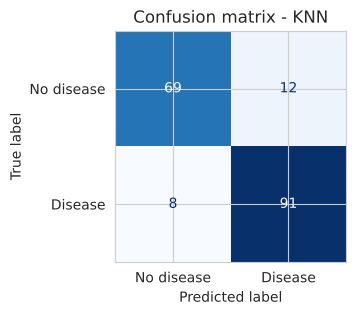

In [18]:
res = evaluate_model(KNeighborsClassifier(), X_train_scaled, X_test_scaled, y_train, y_test, "KNN")
results_before.append(res); show_result(res)

### 5.3 Logistic Regression

{'Model': 'Logistic Regression', 'Accuracy': 0.8722, 'Precision': 0.8725, 'Recall': 0.899, 'F1-score': 0.8856, 'Training Time (s)': 0.002}


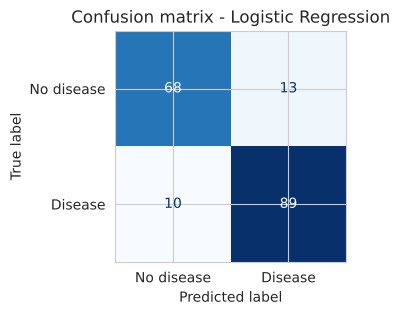

In [19]:
res = evaluate_model(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression")
results_before.append(res); show_result(res)

### 5.4 Decision Tree

{'Model': 'Decision Tree', 'Accuracy': 0.8167, 'Precision': 0.83, 'Recall': 0.8384, 'F1-score': 0.8342, 'Training Time (s)': 0.0021}


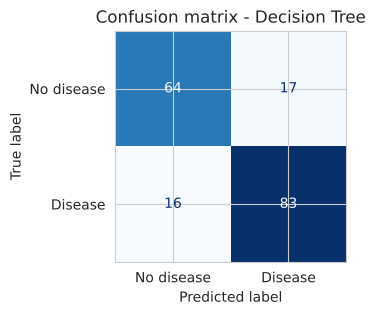

In [20]:
res = evaluate_model(DecisionTreeClassifier(random_state=RANDOM_STATE),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree")
results_before.append(res); show_result(res)

### 5.5 Random Forest

{'Model': 'Random Forest', 'Accuracy': 0.8722, 'Precision': 0.8654, 'Recall': 0.9091, 'F1-score': 0.8867, 'Training Time (s)': 0.1116}


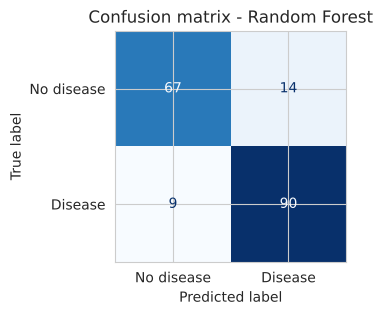

In [21]:
res = evaluate_model(RandomForestClassifier(random_state=RANDOM_STATE),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest")
results_before.append(res); show_result(res)

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,
KNN,0.8889,0.8835,0.9192,0.9010,0.0010
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0020
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0021
Random Forest,0.8722,0.8654,0.9091,0.8867,0.1116


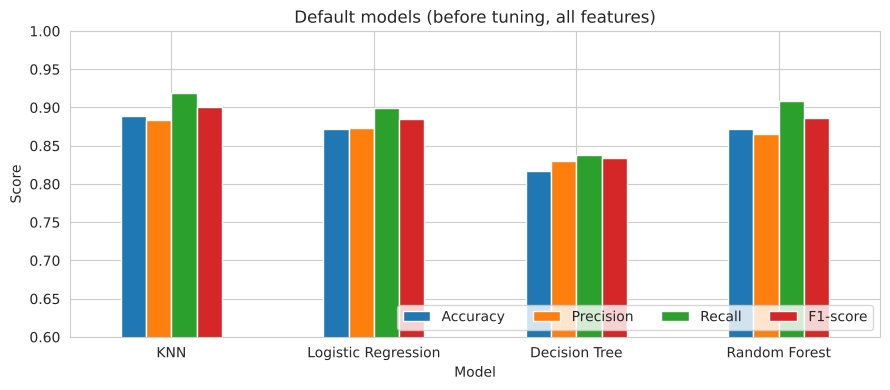

In [22]:
df_before = pd.DataFrame(results_before).set_index("Model")
display(df_before.round(4))

df_before[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(9, 4), rot=0)
plt.title("Default models (before tuning, all features)")
plt.ylabel("Score")
plt.ylim(0.6, 1.0)
plt.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> The **KNN** model had the highest default test accuracy (**88.9%**), followed by Logistic Regression and Random Forest (both 87.2%) and Decision Tree (81.7%). The unpruned Decision Tree overfits the training data, which is why it is clearly the weakest.
>
> In medical diagnosis **accuracy alone is not the most important metric**. A false negative (a sick patient predicted healthy) means a missed diagnosis and delayed treatment, which is generally far more costly than a false positive (a healthy patient sent for further tests). **Recall** (sensitivity) should therefore be prioritised, while keeping precision at a reasonable level (e.g. through F1) so that the number of unnecessary follow-ups stays manageable. KNN also has the highest recall (91.9%) among the default models, so it is the best choice by this criterion too.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": (KNeighborsClassifier(), {
        "n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"],
    }),
    "Logistic Regression": (LogisticRegression(random_state=RANDOM_STATE, max_iter=5000), {
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "penalty": ["l1", "l2"],
        "solver": ["liblinear", "saga"],
    }),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "max_depth": [3, 4, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 5, 10],
        "criterion": ["gini", "entropy"],
    }),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "max_features": ["sqrt", "log2"],
    }),
}

def tune_model(name, X_tr, X_te, y_tr, y_te, show_cm=True):
    """Grid search with stratified K-fold CV on the training set, then evaluate the best model on the test set."""
    estimator, grid = param_grids[name]
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    print(f"Best parameters : {gs.best_params_}")
    print(f"Mean CV accuracy: {gs.best_score_:.4f}")
    # Retrain with the best hyperparameters (timed) and evaluate on the test set
    best = clone(estimator).set_params(**gs.best_params_)
    res = evaluate_model(best, X_tr, X_te, y_tr, y_te, name, show_cm=show_cm)
    res["Best CV Accuracy"] = float(gs.best_score_)
    res["Best Params"] = gs.best_params_
    show_result({k: v for k, v in res.items() if k != "Best Params"})
    return res

results_tuned = []
print("Grids defined for:", list(param_grids.keys()))

Grids defined for: ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']


### 6.2 Tune KNN

Best parameters : {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Mean CV accuracy: 0.8803
{'Model': 'KNN', 'Accuracy': 0.8944, 'Precision': 0.8922, 'Recall': 0.9192, 'F1-score': 0.9055, 'Training Time (s)': 0.001, 'Best CV Accuracy': 0.8803}


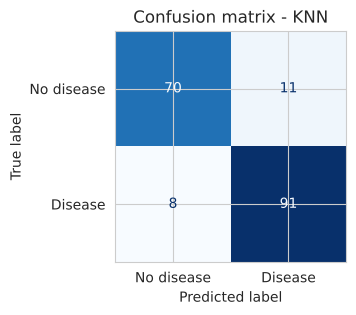

In [24]:
res = tune_model("KNN", X_train_scaled, X_test_scaled, y_train, y_test)
results_tuned.append(res)

### 6.3 Tune Logistic Regression

Best parameters : {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
Mean CV accuracy: 0.8678
{'Model': 'Logistic Regression', 'Accuracy': 0.8778, 'Precision': 0.8738, 'Recall': 0.9091, 'F1-score': 0.8911, 'Training Time (s)': 0.002, 'Best CV Accuracy': 0.8678}


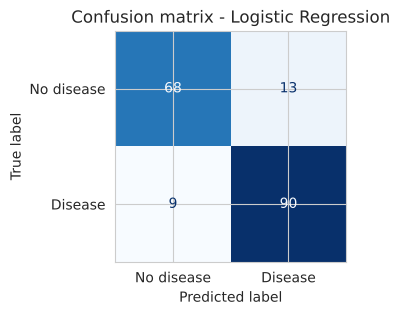

In [25]:
res = tune_model("Logistic Regression", X_train_scaled, X_test_scaled, y_train, y_test)
results_tuned.append(res)

### 6.4 Tune Decision Tree

Best parameters : {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mean CV accuracy: 0.8428
{'Model': 'Decision Tree', 'Accuracy': 0.85, 'Precision': 0.86, 'Recall': 0.8687, 'F1-score': 0.8643, 'Training Time (s)': 0.0021, 'Best CV Accuracy': 0.8428}


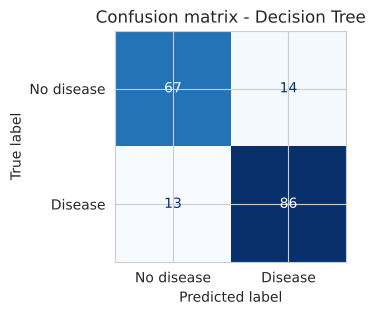

In [26]:
res = tune_model("Decision Tree", X_train_scaled, X_test_scaled, y_train, y_test)
results_tuned.append(res)

### 6.5 Tune Random Forest

Best parameters : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}
Mean CV accuracy: 0.8748
{'Model': 'Random Forest', 'Accuracy': 0.8667, 'Precision': 0.8571, 'Recall': 0.9091, 'F1-score': 0.8824, 'Training Time (s)': 0.4074, 'Best CV Accuracy': 0.8748}


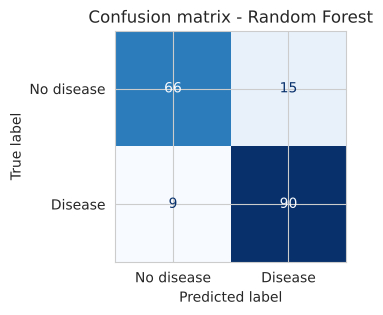

In [27]:
res = tune_model("Random Forest", X_train_scaled, X_test_scaled, y_train, y_test)
results_tuned.append(res)

### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

Best hyperparameters:
  KNN: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
  Logistic Regression: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
  Decision Tree: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
  Random Forest: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}

Change in test metrics after tuning (tuned - default):
Best tuned model (test accuracy): KNN


,Accuracy,Precision,Recall,F1-score,Best CV Accuracy,Training Time (s)
Model,,,,,,
KNN,0.8944,0.8922,0.9192,0.9055,0.8803,0.0010
Logistic Regression,0.8778,0.8738,0.9091,0.8911,0.8678,0.0020
Decision Tree,0.8500,0.8600,0.8687,0.8643,0.8428,0.0021
Random Forest,0.8667,0.8571,0.9091,0.8824,0.8748,0.4074


,Accuracy change,F1 change
Model,,
KNN,0.0056,0.0045
Logistic Regression,0.0056,0.0055
Decision Tree,0.0333,0.0302
Random Forest,-0.0056,-0.0043


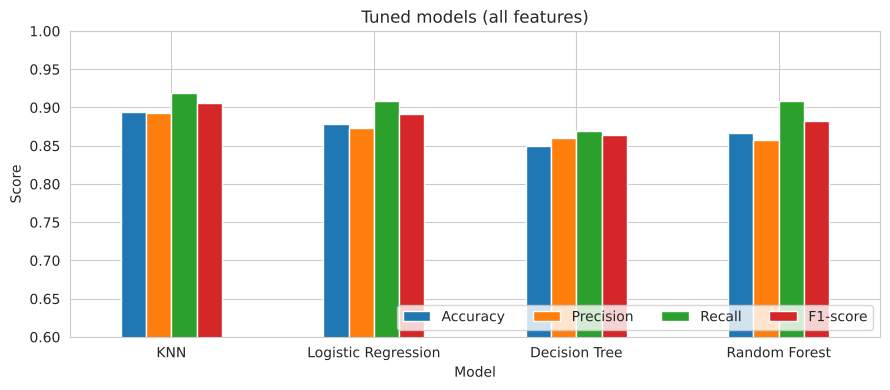

In [28]:
df_tuned = pd.DataFrame(results_tuned).set_index("Model")
display(df_tuned[["Accuracy", "Precision", "Recall", "F1-score", "Best CV Accuracy", "Training Time (s)"]].round(4))
print("Best hyperparameters:")
for m, p in df_tuned["Best Params"].items():
    print(f"  {m}: {p}")

change = (df_tuned[["Accuracy", "F1-score"]] - df_before[["Accuracy", "F1-score"]]).round(4)
change.columns = ["Accuracy change", "F1 change"]
print("\nChange in test metrics after tuning (tuned - default):")
display(change)

df_tuned[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(9, 4), rot=0)
plt.title("Tuned models (all features)")
plt.ylabel("Score"); plt.ylim(0.6, 1.0)
plt.legend(loc="lower right", ncol=4)
plt.tight_layout(); plt.show()
print("Best tuned model (test accuracy):", df_tuned["Accuracy"].idxmax())

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Tuning did **not** improve every model. On the test set: Decision Tree +3.3 percentage points of accuracy (81.7% -> 85.0%), KNN +0.6 pp (88.9% -> 89.4%), Logistic Regression +0.6 pp (87.2% -> 87.8%), while Random Forest dropped slightly by 0.6 pp (87.2% -> 86.7%).
>
> The **Decision Tree benefited the most**. A default tree grows until it fits the training data perfectly, so it overfits; cross-validation selected a shallow tree (`max_depth=4`, `min_samples_leaf=10`) which generalises better. KNN and Logistic Regression were already close to their best settings, and Random Forest is already robust through averaging many trees, so there was little left to gain. Note that the test set has only 180 patients, so one patient is about 0.56 pp: the +/-0.6 pp changes are within noise. The cross-validation scores (0.843-0.880) are a more stable estimate, and tuning picks the best CV score, not necessarily the best test score.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

      Explained variance  Cumulative
PC1               0.2270      0.2270
PC2               0.1129      0.3399
PC3               0.0939      0.4338
PC4               0.0820      0.5158
PC5               0.0779      0.5937
PC6               0.0697      0.6634
PC7               0.0621      0.7255
PC8               0.0555      0.7811
PC9               0.0521      0.8331
PC10              0.0434      0.8766
PC11              0.0395      0.9160
PC12              0.0285      0.9445
PC13              0.0275      0.9720
PC14              0.0215      0.9935
PC15              0.0065      1.0000


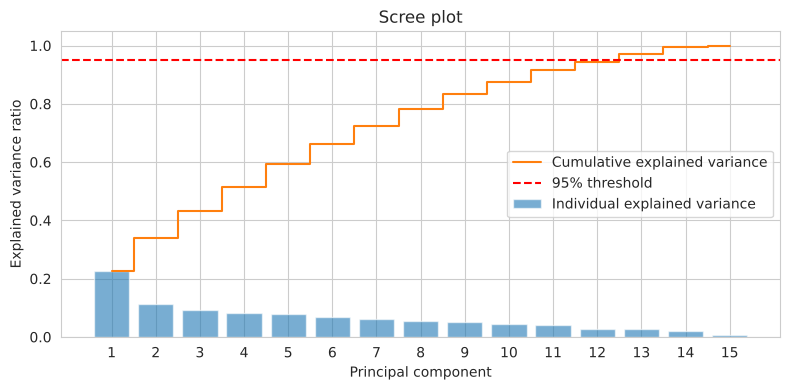

In [29]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)          # fitted on the scaled TRAINING data only

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
components = np.arange(1, len(evr) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(components, evr, alpha=0.6, label="Individual explained variance")
ax.step(components, cum_evr, where="mid", color="C1", label="Cumulative explained variance")
ax.axhline(0.95, color="red", linestyle="--", label="95% threshold")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components)
ax.set_title("Scree plot")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"Explained variance": evr.round(4), "Cumulative": cum_evr.round(4)},
                   index=[f"PC{i}" for i in components]))

### 7.2 Determine the number of components for 95% variance

In [30]:
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)
print("Original number of features:", X_train_scaled.shape[1])
print("Components needed for >= 95% variance:", n_95)
print("Variance retained with", n_95, "components:", round(cum_evr[n_95 - 1], 4))

# Equivalent shortcut: PCA(n_components=0.95)
pca = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train_scaled)
print("PCA(n_components=0.95) chose:", pca.n_components_, "components")

Original number of features: 15
Components needed for >= 95% variance: 13
Variance retained with 13 components: 0.972
PCA(n_components=0.95) chose: 13 components


### 7.3 Transform the training and testing sets

In [31]:
X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)    # transform only - no refitting on test data

print("Before PCA -> X_train:", X_train_scaled.shape, "| X_test:", X_test_scaled.shape)
print("After  PCA -> X_train:", X_train_pca.shape, "| X_test:", X_test_pca.shape)
reduction = (1 - pca.n_components_ / X_train_scaled.shape[1]) * 100
print(f"Feature reduction: {reduction:.1f}%")

Before PCA -> X_train: (719, 15) | X_test: (180, 15)
After  PCA -> X_train: (719, 13) | X_test: (180, 13)
Feature reduction: 13.3%


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

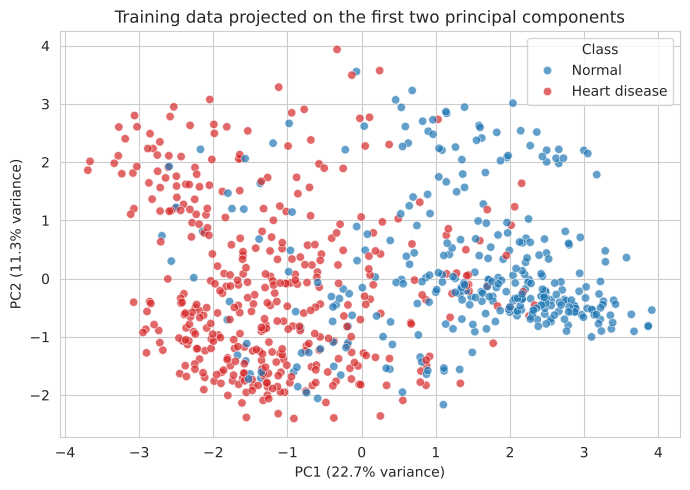

In [32]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
X_2d = pca2.transform(X_train_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_train.map({0: "Normal", 1: "Heart disease"}),
                palette={"Normal": "tab:blue", "Heart disease": "tab:red"}, alpha=0.7)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Training data projected on the first two principal components")
plt.legend(title="Class")
plt.tight_layout(); plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> **13 principal components** are needed to retain at least 95% of the variance (they capture about 97.2%; 12 components give only 94.5%). The number of features is therefore reduced from 15 to 13, a reduction of only **about 13.3%**.
>
> The reduction is small because the encoded features are largely independent: the first component explains only 22.7% of the variance, and the variance is spread fairly evenly over many components (the scree plot has no sharp elbow). The dataset has few, mostly weakly correlated features, so there is not much redundancy for PCA to remove.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

Best parameters : {'metric': 'manhattan', 'n_neighbors': 21, 'weights': 'distance'}
Mean CV accuracy: 0.8762
{'Model': 'KNN', 'Accuracy': 0.9111, 'Precision': 0.9109, 'Recall': 0.9293, 'F1-score': 0.92, 'Training Time (s)': 0.0008, 'Best CV Accuracy': 0.8762}


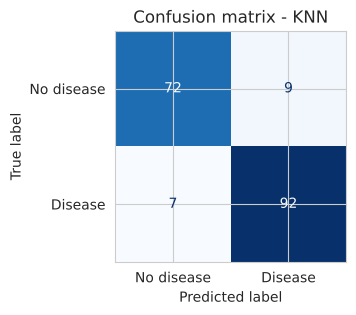

In [33]:
results_pca = []
res = tune_model("KNN", X_train_pca, X_test_pca, y_train, y_test)
results_pca.append(res)

### 8.2 Logistic Regression after PCA

Best parameters : {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Mean CV accuracy: 0.8678
{'Model': 'Logistic Regression', 'Accuracy': 0.8778, 'Precision': 0.8812, 'Recall': 0.899, 'F1-score': 0.89, 'Training Time (s)': 0.0015, 'Best CV Accuracy': 0.8678}


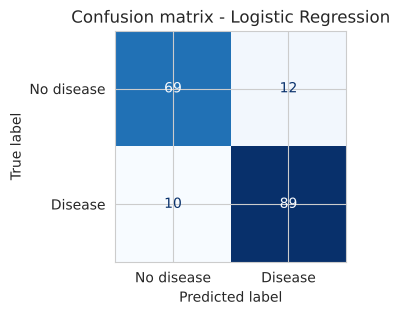

In [34]:
res = tune_model("Logistic Regression", X_train_pca, X_test_pca, y_train, y_test)
results_pca.append(res)

### 8.3 Decision Tree after PCA

Best parameters : {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mean CV accuracy: 0.8400
{'Model': 'Decision Tree', 'Accuracy': 0.8056, 'Precision': 0.881, 'Recall': 0.7475, 'F1-score': 0.8087, 'Training Time (s)': 0.0041, 'Best CV Accuracy': 0.84}


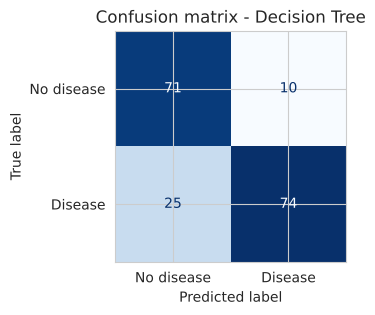

In [35]:
res = tune_model("Decision Tree", X_train_pca, X_test_pca, y_train, y_test)
results_pca.append(res)

### 8.4 Random Forest after PCA

Best parameters : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Mean CV accuracy: 0.8692
{'Model': 'Random Forest', 'Accuracy': 0.8944, 'Precision': 0.8846, 'Recall': 0.9293, 'F1-score': 0.9064, 'Training Time (s)': 0.1208, 'Best CV Accuracy': 0.8692}


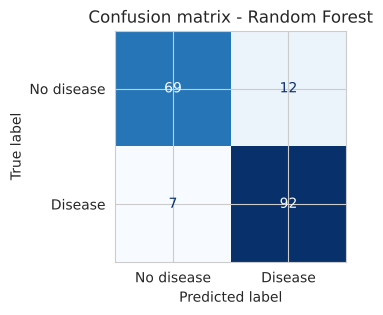

In [36]:
res = tune_model("Random Forest", X_train_pca, X_test_pca, y_train, y_test)
results_pca.append(res)

### 8.5 Comparison table of all four models after PCA

In [37]:
df_pca = pd.DataFrame(results_pca).set_index("Model")
display(df_pca[["Accuracy", "Precision", "Recall", "F1-score", "Best CV Accuracy", "Training Time (s)"]].round(4))
print("Best hyperparameters (after PCA):")
for m, p in df_pca["Best Params"].items():
    print(f"  {m}: {p}")
print("\nBest model after PCA (test accuracy):", df_pca["Accuracy"].idxmax())
print("Best model before PCA (tuned, test accuracy):", df_tuned["Accuracy"].idxmax())

Best hyperparameters (after PCA):
  KNN: {'metric': 'manhattan', 'n_neighbors': 21, 'weights': 'distance'}
  Logistic Regression: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
  Decision Tree: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
  Random Forest: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}

Best model after PCA (test accuracy): KNN
Best model before PCA (tuned, test accuracy): KNN


,Accuracy,Precision,Recall,F1-score,Best CV Accuracy,Training Time (s)
Model,,,,,,
KNN,0.9111,0.9109,0.9293,0.9200,0.8762,0.0008
Logistic Regression,0.8778,0.8812,0.8990,0.8900,0.8678,0.0015
Decision Tree,0.8056,0.8810,0.7475,0.8087,0.8400,0.0041
Random Forest,0.8944,0.8846,0.9293,0.9064,0.8692,0.1208


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA the best model is **KNN** again (test accuracy **91.1%**, F1 0.920), followed by Random Forest (89.4%), Logistic Regression (87.8%) and Decision Tree (80.6%). So **yes, it is the same model that performed best before PCA** (tuned KNN, 89.4%). The ranking of the other models changed slightly: Random Forest moved ahead of Logistic Regression, which now ties with its previous score.
>
> The Decision Tree is again the weakest, and its recall dropped to 74.8%, meaning it misses about one in four patients with heart disease, which is a poor result for a diagnostic tool.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
# "Before PCA" = tuned models on all features (Task 6); "After PCA" = tuned models on PCA features (Task 8)
comparison = pd.DataFrame({
    "Accuracy (Before PCA)": df_tuned["Accuracy"],
    "Accuracy (After PCA)": df_pca["Accuracy"],
    "F1 (Before PCA)": df_tuned["F1-score"],
    "F1 (After PCA)": df_pca["F1-score"],
    "Training Time Before (s)": df_tuned["Training Time (s)"],
    "Training Time After (s)": df_pca["Training Time (s)"],
    "No. of Features": [f"{X_train_scaled.shape[1]} -> {X_train_pca.shape[1]}"] * len(df_tuned),
})
display(comparison.round(4))

# Reference: default (untuned) models on all features, for completeness
print("Reference - default models before tuning:")
display(df_before[["Accuracy", "F1-score", "Training Time (s)"]].round(4))

Reference - default models before tuning:


,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
Model,,,,,,,
KNN,0.8944,0.9111,0.9055,0.9200,0.0010,0.0008,15 -> 13
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0020,0.0015,15 -> 13
Decision Tree,0.8500,0.8056,0.8643,0.8087,0.0021,0.0041,15 -> 13
Random Forest,0.8667,0.8944,0.8824,0.9064,0.4074,0.1208,15 -> 13


,Accuracy,F1-score,Training Time (s)
Model,,,
KNN,0.8889,0.9010,0.0010
Logistic Regression,0.8722,0.8856,0.0020
Decision Tree,0.8167,0.8342,0.0021
Random Forest,0.8722,0.8867,0.1116


### 9.2 Visualise the before vs after PCA comparison

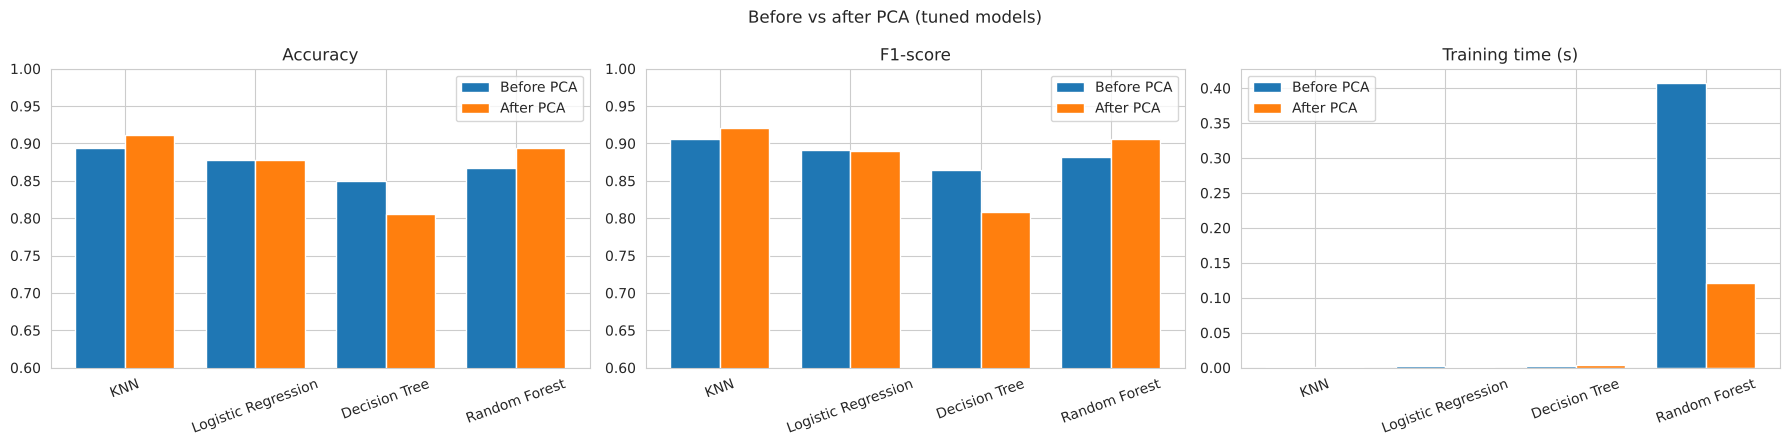

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
idx = np.arange(len(comparison)); w = 0.38

axes[0].bar(idx - w/2, comparison["Accuracy (Before PCA)"], w, label="Before PCA")
axes[0].bar(idx + w/2, comparison["Accuracy (After PCA)"], w, label="After PCA")
axes[0].set_title("Accuracy"); axes[0].set_ylim(0.6, 1.0)

axes[1].bar(idx - w/2, comparison["F1 (Before PCA)"], w, label="Before PCA")
axes[1].bar(idx + w/2, comparison["F1 (After PCA)"], w, label="After PCA")
axes[1].set_title("F1-score"); axes[1].set_ylim(0.6, 1.0)

axes[2].bar(idx - w/2, comparison["Training Time Before (s)"], w, label="Before PCA")
axes[2].bar(idx + w/2, comparison["Training Time After (s)"], w, label="After PCA")
axes[2].set_title("Training time (s)")

for ax in axes:
    ax.set_xticks(idx); ax.set_xticklabels(comparison.index, rotation=20)
    ax.legend()
plt.suptitle("Before vs after PCA (tuned models)")
plt.tight_layout(); plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Comparing tuned models before and after PCA (test accuracy / F1):
>
> - **KNN improved**: 89.4% -> 91.1% accuracy, F1 0.906 -> 0.920.
> - **Random Forest improved**: 86.7% -> 89.4% accuracy, F1 0.882 -> 0.906.
> - **Logistic Regression was unchanged**: 87.8% accuracy in both cases (F1 0.891 vs 0.890).
> - **Decision Tree declined**: 85.0% -> 80.6% accuracy, F1 0.864 -> 0.809.
>
> These differences should be read with care: the test set has only 180 samples, so one patient is 0.56 pp and the changes correspond to a handful of patients. The 5-fold CV accuracy on the training data tells a more cautious story: it stayed the same or fell slightly after PCA (KNN 0.880 -> 0.876, Logistic Regression 0.868 -> 0.868, Random Forest 0.875 -> 0.869, Decision Tree 0.843 -> 0.840). So there is no consistent evidence that PCA improved performance; the apparent gains for KNN and Random Forest are partly the luck of this particular split.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> PCA reduced the number of features only from 15 to 13 (about 13%), so the efficiency gain is small. Average training times (tuned models, mean of 10 fits): Random Forest **0.407 s -> 0.121 s** (about 70% faster), KNN 1.0 ms -> 0.8 ms, Logistic Regression 2.0 ms -> 1.5 ms. The Decision Tree actually became slower (2.1 ms -> 4.1 ms), because PCA components are continuous, so a tree has many more candidate split thresholds to evaluate than with binary dummy variables.
>
> Caveats: the Random Forest speed-up is mostly due to the different best hyperparameters (100 trees with depth 5 after PCA vs 300 trees with unlimited depth before), not only to the fewer features; the other times are only milliseconds and strongly affected by system noise; and the cost of fitting and applying PCA itself (not included in the times above) must also be paid. On a dataset this small the practical gain in computational efficiency is negligible.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> On this dataset PCA **did not clearly improve or reduce** classification performance: two models scored higher on the test set, one was identical and one was worse, and the cross-validation scores were flat or slightly lower. Possible reasons:
>
> - **Small dataset and few features (15)**: little redundancy to remove, and 13 of 15 components were needed to keep 95% of the variance, so PCA acts mostly as a rotation of the data rather than as a real reduction.
> - **PCA ignores the target**: it keeps directions of maximum variance, not those that best separate the classes. The one-hot/binary features (e.g. `ST_Slope`, `ExerciseAngina`) are very predictive but may have small variance, so information can be lost in the discarded components.
> - **Model type**: distance-based KNN and linear models can benefit from decorrelated, rotated features, whereas tree-based models work on the original features with axis-aligned splits, which PCA components destroy. This fits the decline of the Decision Tree.
> - **Evaluation noise**: with 180 test records, differences of 1-3% are only a few patients.
> - **Interpretability**: each component is a mix of all original features, so we can no longer say that, for example, `Oldpeak` or `MaxHR` drives a prediction, which matters in a medical setting.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> PCA lets us trade a (possibly small) amount of **predictive accuracy and interpretability** for **lower computational cost and lower dimensionality**: fewer features mean less memory, faster training and prediction, less overfitting and no multicollinearity, but information can be lost and the components are hard to explain. Which side is more important depends on the application: when a few percentage points of accuracy or explainability matter more than speed (as in clinical diagnosis with only about 900 patients and 15 features), the original features are preferable.
>
> PCA is preferable when:
> - there are **many (hundreds or thousands) correlated features**, e.g. images, gene-expression data, spectra, text embeddings or sensor streams;
> - the dataset is **large** or models must be retrained or run in real time or on limited hardware, so speed and memory matter;
> - the model suffers from the **curse of dimensionality** (KNN, clustering) or **multicollinearity** (linear models);
> - we want to **visualise** high-dimensional data in 2D/3D, to compress data or to remove noise.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.